Daily Weather

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("Daily Weather.csv")

Level 1 – Basic Questions

In [3]:
# 1. What is the shape of the dataset?
print("Shape of Dataset:",df.shape)

Shape of Dataset: (1095, 11)


In [4]:
# 2. How many columns and rows are present?
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])

Rows: 1095
Columns: 11


In [5]:
# 3. What are the column names?
print("Co lumn names:", df.columns)

Co lumn names: Index(['number', 'air_pressure_9am', 'air_temp_9am', 'avg_wind_direction_9am',
       'avg_wind_speed_9am', 'max_wind_direction_9am', 'max_wind_speed_9am',
       'rain_accumulation_9am', 'rain_duration_9am', 'relative_humidity_9am',
       'relative_humidity_3pm'],
      dtype='object')


In [6]:
# 4. Check the first 5 rows of the dataset.
print(df.head())

   number  air_pressure_9am  air_temp_9am  avg_wind_direction_9am  \
0       0        918.060000     74.822000              271.100000   
1       1        917.347688     71.403843              101.935179   
2       2        923.040000     60.638000               51.000000   
3       3        920.502751     70.138895              198.832133   
4       4        921.160000     44.294000              277.800000   

   avg_wind_speed_9am  max_wind_direction_9am  max_wind_speed_9am  \
0            2.080354              295.400000            2.863283   
1            2.443009              140.471548            3.533324   
2           17.067852               63.700000           22.100967   
3            4.337363              211.203341            5.190045   
4            1.856660              136.500000            2.863283   

   rain_accumulation_9am  rain_duration_9am  relative_humidity_9am  \
0                    0.0                0.0              42.420000   
1                    0.0      

In [7]:
# 5. Identify the data types of each column.
print("Datatypes of Each Column:",df.dtypes)

Datatypes of Each Column: number                      int64
air_pressure_9am          float64
air_temp_9am              float64
avg_wind_direction_9am    float64
avg_wind_speed_9am        float64
max_wind_direction_9am    float64
max_wind_speed_9am        float64
rain_accumulation_9am     float64
rain_duration_9am         float64
relative_humidity_9am     float64
relative_humidity_3pm     float64
dtype: object


In [8]:
# 6. Are there any missing values in the dataset? Show them.
print("Missing Values:",df.isnull().sum())

Missing Values: number                    0
air_pressure_9am          3
air_temp_9am              5
avg_wind_direction_9am    4
avg_wind_speed_9am        3
max_wind_direction_9am    3
max_wind_speed_9am        4
rain_accumulation_9am     6
rain_duration_9am         3
relative_humidity_9am     0
relative_humidity_3pm     0
dtype: int64


In [9]:
# 7. How many unique values are in each column?
print("Unique Values:",df.nunique())

Unique Values: number                    1095
air_pressure_9am          1070
air_temp_9am              1089
avg_wind_direction_9am    1004
avg_wind_speed_9am        1087
max_wind_direction_9am     992
max_wind_speed_9am        1088
rain_accumulation_9am       98
rain_duration_9am          142
relative_humidity_9am     1094
relative_humidity_3pm     1094
dtype: int64


In [10]:
# 8. Find the summary statistics (mean, median, min, max) for all numeric columns.
print("Summary Statistics:\n",df.describe())

Summary Statistics:
             number  air_pressure_9am  air_temp_9am  avg_wind_direction_9am  \
count  1095.000000       1092.000000   1090.000000             1091.000000   
mean    547.000000        918.882551     64.933001              142.235511   
std     316.243577          3.184161     11.175514               69.137859   
min       0.000000        907.990000     36.752000               15.500000   
25%     273.500000        916.550000     57.281000               65.972506   
50%     547.000000        918.921045     65.715479              166.000000   
75%     820.500000        921.160073     73.450974              191.000000   
max    1094.000000        929.320000     98.906000              343.400000   

       avg_wind_speed_9am  max_wind_direction_9am  max_wind_speed_9am  \
count         1092.000000             1092.000000         1091.000000   
mean             5.508284              148.953518            7.019514   
std              4.552813               67.238013        

In [11]:
# 9. Count the number of duplicate rows.
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
# 10. Rename one of the columns to a more readable name.
df.rename(columns={"air_temp_9am": "temperature_9am"}, inplace=True)

In [13]:
# 11. Which column has the highest average value?
print("Column with Highest Average Value:", df.mean().idxmax())

Column with Highest Average Value: air_pressure_9am


In [14]:
# 12. Which column has the lowest average value?
print("Column with Lowest Average Value:", df.mean().idxmin())

Column with Lowest Average Value: rain_accumulation_9am


In [15]:
# 13. Find the most common value in a categorical column.
# Create temperature category column
df1 = df.copy()
def temp_category(temp):
    if temp < 60:
        return "Cold"
    elif temp < 80:
        return "Normal"
    else:
        return "Hot"

df1["temp_category"] = df1["temperature_9am"].apply(temp_category)

print(df1[["temperature_9am", "temp_category"]].head())

   temperature_9am temp_category
0        74.822000        Normal
1        71.403843        Normal
2        60.638000        Normal
3        70.138895        Normal
4        44.294000          Cold


In [16]:
most_common = df1["temp_category"].mode()[0]
print("Most Common Temperature Category:", most_common)

Most Common Temperature Category: Normal


In [17]:
# 14. Count the frequency of each category
category_counts = df1["temp_category"].value_counts()
print("Category Frequencies:\n", category_counts)

Category Frequencies:
 temp_category
Normal    660
Cold      349
Hot        86
Name: count, dtype: int64


In [18]:
# 15. Calculate the correlation between two numerical columns
corr = df["avg_wind_direction_9am"].corr(df["avg_wind_speed_9am"])
print("Correlation between avg_wind_direction_9am and avg_wind_speed_9am:", corr)

Correlation between avg_wind_direction_9am and avg_wind_speed_9am: -0.43295064965437835


In [19]:
# 16. Which numerical column has the highest standard deviation?
print("Column with Highest Standard Deviation:", df.std().idxmax())


Column with Highest Standard Deviation: rain_duration_9am


In [20]:
# 18. Display the top 10 records based on a numerical column.
top_10 = df.sort_values(by="temperature_9am", ascending=False).head(10)
print("Top 10 Records by temperature_9am:\n", top_10)

Top 10 Records by temperature_9am:
      number  air_pressure_9am  temperature_9am  avg_wind_direction_9am  \
720     720            913.70           98.906                   192.7   
30       30            919.35           91.112                    96.4   
662     662            917.16           90.266                   331.8   
312     312            915.10           89.780                   159.5   
260     260            916.65           89.402                   185.2   
872     872            918.20           89.204                   225.5   
128     128            916.04           88.844                   176.0   
739     739            919.10           87.602                   275.7   
907     907            918.60           87.440                    40.9   
461     461            915.60           87.314                    15.5   

     avg_wind_speed_9am  max_wind_direction_9am  max_wind_speed_9am  \
720            2.125093                    53.4            3.355410   
30     

In [21]:
# 19. Find the minimum and maximum value of a numerical column.
min_value = df["temperature_9am"].min()
max_value = df["temperature_9am"].max()
print("Minimum temperature_9am:", min_value)
print("Maximum temperature_9am:", max_value)

Minimum temperature_9am: 36.752000000000685
Maximum temperature_9am: 98.90599999999992


In [22]:
# 20. Convert a categorical column into numerical form using label encoding.
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df1["temp_category_encoded"] = le.fit_transform(df1["temp_category"])
print("Label Encoded Temperature Categories:\n", df1[["temp_category", "temp_category_encoded"]].head())


Label Encoded Temperature Categories:
   temp_category  temp_category_encoded
0        Normal                      2
1        Normal                      2
2        Normal                      2
3        Normal                      2
4          Cold                      0


Level 2 – Intermediate Questions

In [23]:
# 1. Handle missing values by filling them with the median.
df.fillna(df.median(), inplace=True)

In [24]:
# 2. Drop rows with missing values.
df2=df.dropna(inplace=True)

In [25]:
# 3. Normalize a numerical column using MinMaxScaler.
from sklearn.preprocessing import MinMaxScaler
scaler_minmax=MinMaxScaler()
df['air_pressure_9am_normalized']=scaler_minmax.fit_transform(df[['air_pressure_9am']])
print(df[['air_pressure_9am','air_pressure_9am_normalized']].head())

   air_pressure_9am  air_pressure_9am_normalized
0        918.060000                     0.472105
1        917.347688                     0.438710
2        923.040000                     0.705579
3        920.502751                     0.586627
4        921.160000                     0.617440


In [26]:
# 4. Standardize a numerical column using StandardScaler.
from sklearn.preprocessing import StandardScaler
scaler_std=StandardScaler()
df['air_pressure_9am_standardized']=scaler_std.fit_transform(df[['air_pressure_9am']])
print(df[['air_pressure_9am','air_pressure_9am_standardized']].head())

   air_pressure_9am  air_pressure_9am_standardized
0        918.060000                      -0.258832
1        917.347688                      -0.482947
2        923.040000                       1.308023
3        920.502751                       0.509730
4        921.160000                       0.716520


In [27]:
# 5. Create a new column based on an existing one using a mathematical operation.
df['air_pressure_9am_squared'] = df['air_pressure_9am'] ** 2
print(df[['air_pressure_9am', 'air_pressure_9am_squared']].head())  

   air_pressure_9am  air_pressure_9am_squared
0        918.060000             842834.163600
1        917.347688             841526.780895
2        923.040000             852002.841600
3        920.502751             847325.314922
4        921.160000             848535.745600


In [28]:
# 6. Change the data type of a column from float to int.
df['avg_wind_speed_9am']=df['avg_wind_speed_9am'].astype(int)
print(df['avg_wind_speed_9am'].dtypes)

int32


In [29]:
# 7. Apply one-hot encoding to a categorical column.
df_encoded = pd.get_dummies(df1, columns=['temp_category'], prefix='temp_cat')
print(df_encoded.head())

   number  air_pressure_9am  temperature_9am  avg_wind_direction_9am  \
0       0        918.060000        74.822000              271.100000   
1       1        917.347688        71.403843              101.935179   
2       2        923.040000        60.638000               51.000000   
3       3        920.502751        70.138895              198.832133   
4       4        921.160000        44.294000              277.800000   

   avg_wind_speed_9am  max_wind_direction_9am  max_wind_speed_9am  \
0            2.080354              295.400000            2.863283   
1            2.443009              140.471548            3.533324   
2           17.067852               63.700000           22.100967   
3            4.337363              211.203341            5.190045   
4            1.856660              136.500000            2.863283   

   rain_accumulation_9am  rain_duration_9am  relative_humidity_9am  \
0                    0.0                0.0              42.420000   
1           

In [30]:
# 8. Replace specific values in a column with new values.
df1['temp_category'].replace({'Cold': 'Chilly', 'Normal': 'Mild', 'Hot': 'Warm'}, inplace=True)
print(df1['temp_category'].head())

0      Mild
1      Mild
2      Mild
3      Mild
4    Chilly
Name: temp_category, dtype: object


C:\Users\Sadiya\AppData\Local\Temp\ipykernel_27940\157622936.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1['temp_category'].replace({'Cold': 'Chilly', 'Normal': 'Mild', 'Hot': 'Warm'}, inplace=True)


In [31]:
# 9. Detect and remove outliers using the IQR method. 
Q1= df['temperature_9am'].quantile(0.25)
Q3= df['temperature_9am'].quantile(0.75)
IQR= Q3 - Q1
lower_bound= Q1 - 1.5 * IQR
upper_bound= Q3 + 1.5 * IQR
df_no_outliers= df[(df['temperature_9am'] >= lower_bound) & (df['temperature_9am'] <= upper_bound)]
print("Dataframe shape after removing outliers:", df_no_outliers.shape)

Dataframe shape after removing outliers: (1094, 14)


In [32]:
# 10. Merge two datasets on a common key. 
# First dataset: basic weather info
df3 = df[["number", "temperature_9am", "relative_humidity_9am"]]

# Second dataset: wind info
df4 = df[["number", "avg_wind_speed_9am", "max_wind_speed_9am"]]


In [33]:
merged_df = pd.merge(df3, df4, on="number", how="inner")

print(merged_df.head())

   number  temperature_9am  relative_humidity_9am  avg_wind_speed_9am  \
0       0        74.822000              42.420000                   2   
1       1        71.403843              24.328697                   2   
2       2        60.638000               8.900000                  17   
3       3        70.138895              12.189102                   4   
4       4        44.294000              92.410000                   1   

   max_wind_speed_9am  
0            2.863283  
1            3.533324  
2           22.100967  
3            5.190045  
4            2.863283  


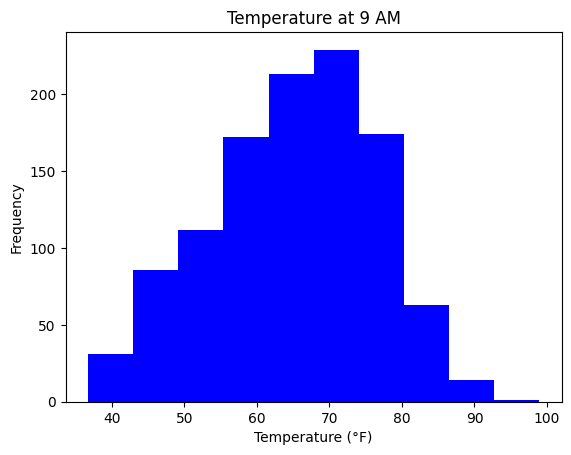

In [34]:
# 11. Plot a histogram for a numerical column.
plt.hist(df['temperature_9am'], color='blue')
plt.title('Temperature at 9 AM')
plt.xlabel('Temperature (°F)')
plt.ylabel('Frequency')
plt.show()


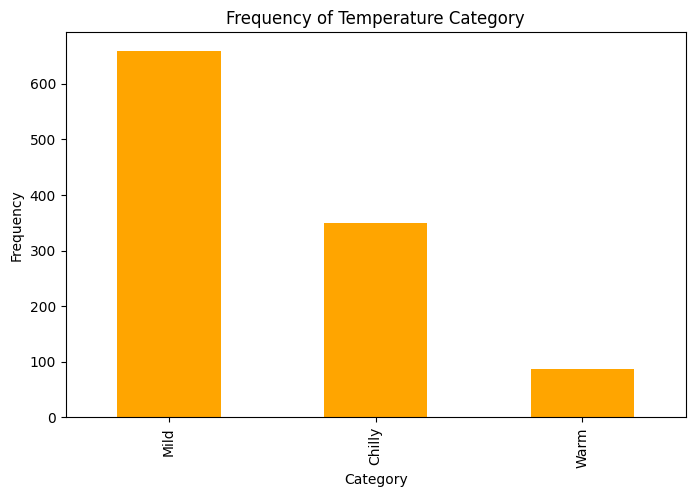

In [35]:
# 12. Plot a bar chart for the frequency of categories in a column.
plt.figure(figsize=(8,5))
df1['temp_category'].value_counts().plot(kind='bar', color='orange')
plt.title('Frequency of Temperature Category')
plt.xlabel('Category')
plt.ylabel('Frequency')
plt.show()


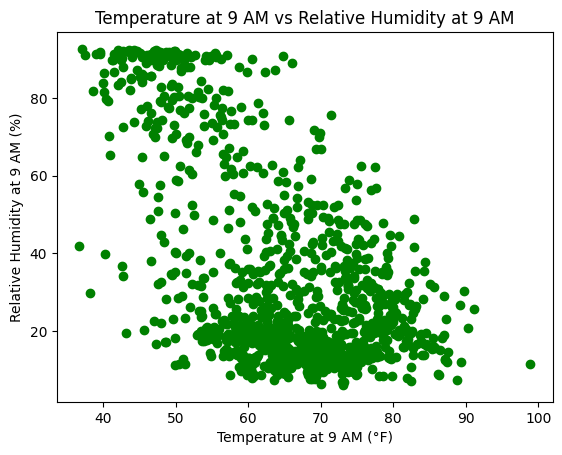

In [36]:
# 13. Create a scatter plot between two numerical columns.
plt.scatter(df['temperature_9am'], df['relative_humidity_9am'], color='green')
plt.title('Temperature at 9 AM vs Relative Humidity at 9 AM')
plt.xlabel('Temperature at 9 AM (°F)')
plt.ylabel('Relative Humidity at 9 AM (%)')
plt.show()

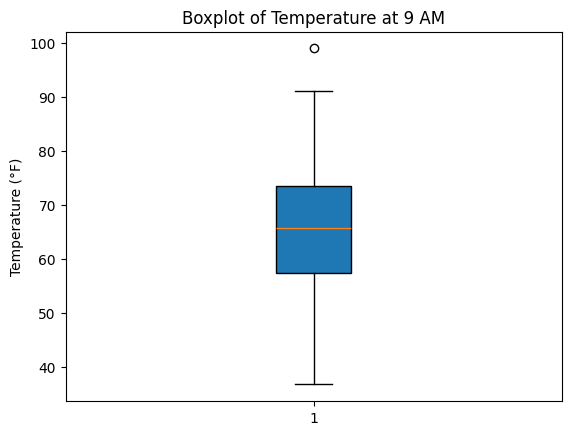

In [37]:
# 14. Plot a boxplot for detecting outliers in a numerical column.
plt.boxplot(df['temperature_9am'], patch_artist=True)
plt.title('Boxplot of Temperature at 9 AM')
plt.ylabel('Temperature (°F)')
plt.show()

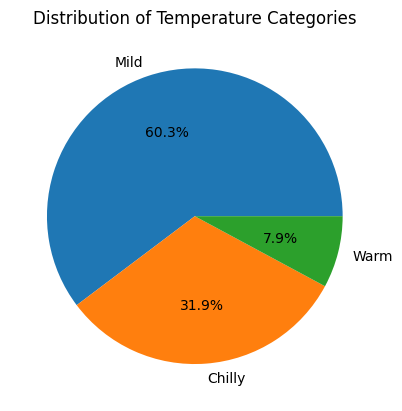

In [38]:
# 15. Plot a pie chart for category distribution.
df1['temp_category'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Distribution of Temperature Categories')
plt.ylabel('')
plt.show()

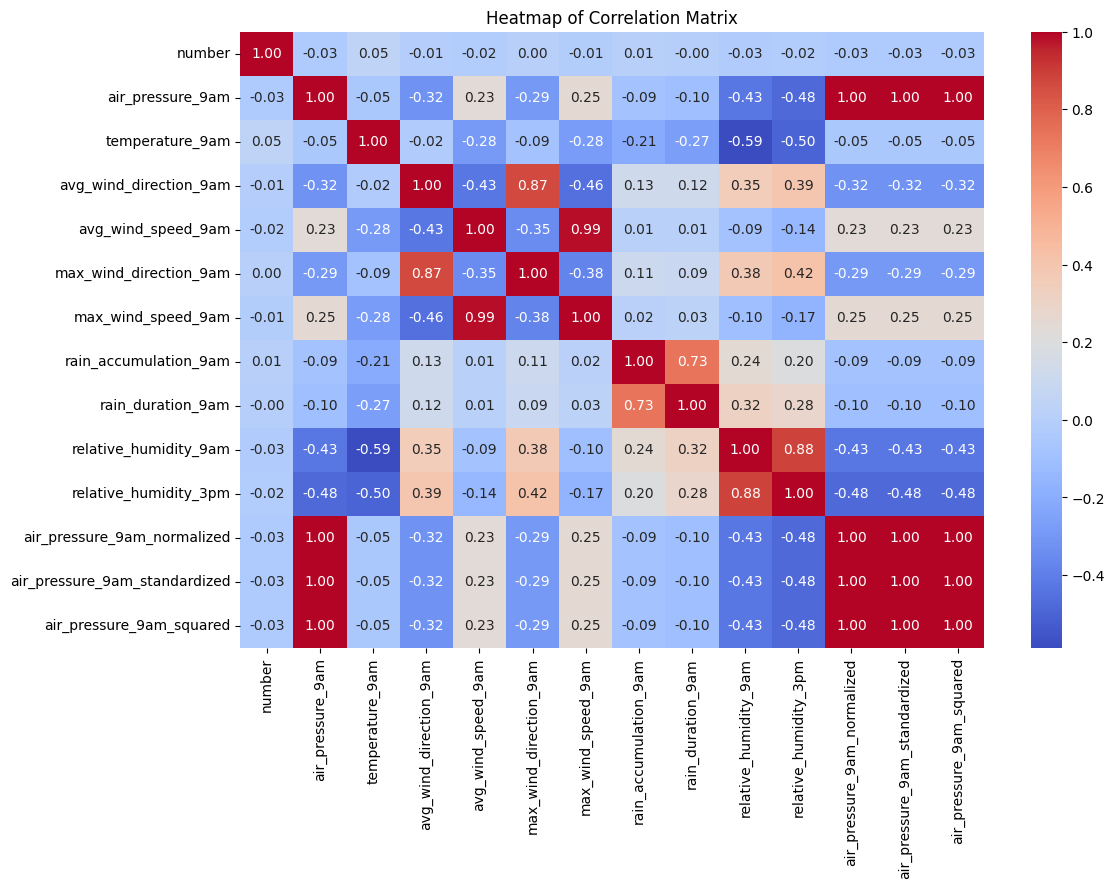

In [39]:
# 16. Create a heatmap of correlations between numerical columns.
import seaborn as sns
plt.figure(figsize=(12,8))  
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Heatmap of Correlation Matrix')
plt.show()

In [40]:
# 17. Draw a line chart showing trends over time (if a date column exists).
# No date column exists in the dataset provided.

In [41]:
# 18. Group the dataset by a categorical column and calculate the mean of a numerical column.
grouped_mean = df1.groupby('temp_category')['temperature_9am'].mean()
print("Mean Temperature by Category:\n", grouped_mean)              

Mean Temperature by Category:
 temp_category
Chilly    51.769923
Mild      69.559903
Warm      83.947315
Name: temperature_9am, dtype: float64


<Figure size 1800x800 with 0 Axes>

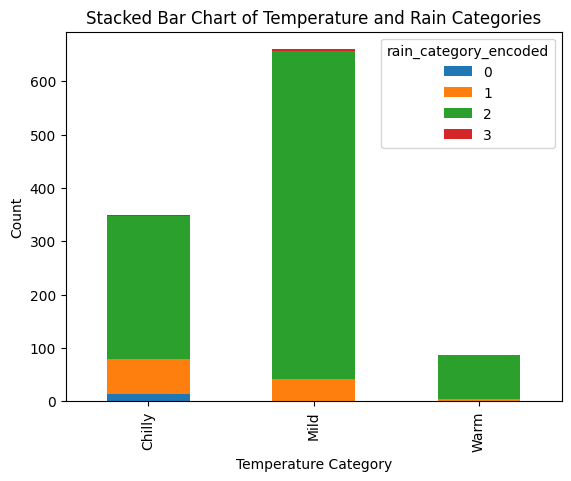

In [42]:
# 19. Create a stacked bar chart comparing two categorical variables.
# No second categorical variable exists in the dataset provided.
# Step 1: Create categories
df1["rain_category"] = pd.cut(
    df1["rain_accumulation_9am"],
    bins=[-1, 0, 5, 100],
    labels=["No Rain", "Light Rain", "Heavy Rain"]
)

# Step 2: Label encode
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df1["rain_category_encoded"] = le.fit_transform(df1["rain_category"])


plt.figure(figsize=(18,8))
df1.groupby('temp_category')['rain_category_encoded'].value_counts().unstack().plot(kind='bar', stacked=True)
plt.title('Stacked Bar Chart of Temperature and Rain Categories')
plt.xlabel('Temperature Category')
plt.ylabel('Count')
plt.show()


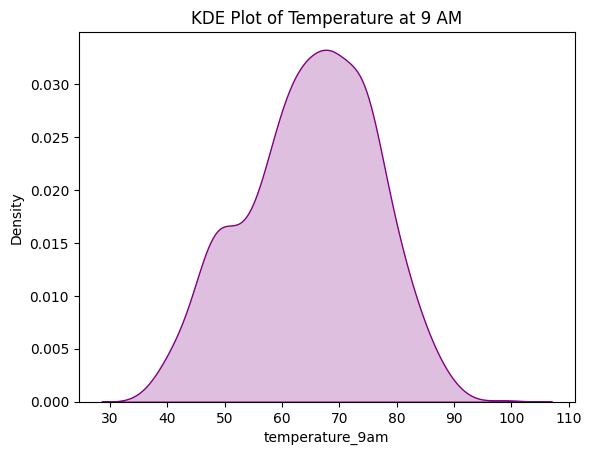

In [43]:
# 20. Show the distribution of a numerical column using sns.kdeplot().
sns.kdeplot(df['temperature_9am'], color='purple', fill=True)
plt.title('KDE Plot of Temperature at 9 AM')
plt.show()